# crosstab
- Compare categorical columns

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('data_titanic.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


# crosstab(): Compare 2 categorical columns

# Basic Crosstab (Sex vs Survival)

In [4]:
ct = pd.crosstab(df['Sex'], df['Survived'])
ct

Survived,0,1
Sex,,
female,81,233
male,468,109


### Insight:

- Shows how many males/females survived or not
- For example: 233 females have survived status=1

<Axes: title={'center': 'Survival Count by Gender'}, xlabel='Sex'>

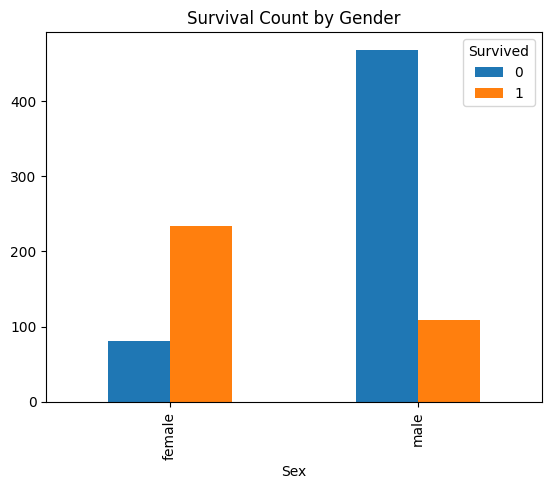

In [9]:
# Bar Plot

ct = pd.crosstab(df['Sex'], df['Survived'])
ct.plot(kind='bar', title='Survival Count by Gender')

<Axes: title={'center': 'Survival Distribution by Gender'}, xlabel='Sex'>

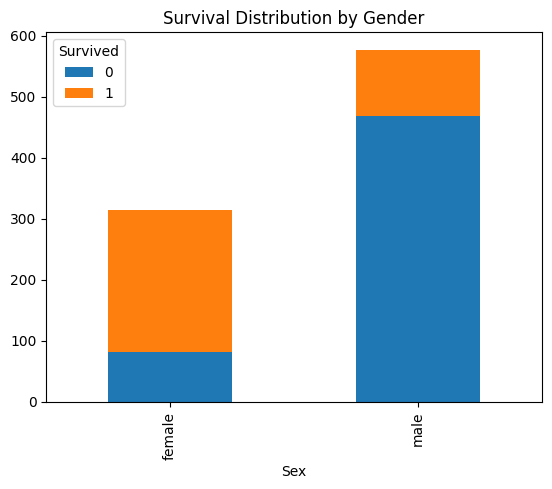

In [10]:
# Stacked Bar Plot
ct = pd.crosstab(df['Sex'], df['Survived'])
ct.plot(kind='bar', stacked=True, title='Survival Distribution by Gender')

In [ ]:
# Add column names

In [5]:
ct = pd.crosstab(df['Sex'], df['Survived'], colnames=['Survival Status'])
ct

Survival Status,0,1
Sex,,
female,81,233
male,468,109


# Add margins (totals)

In [6]:
ct = pd.crosstab(df['Sex'], df['Survived'], margins=True)
ct

Survived,0,1,All
Sex,,,
female,81,233,314
male,468,109,577
All,549,342,891


# Normalize (percentage view)

In [11]:
ct = pd.crosstab(df['Sex'], df['Survived'], normalize='index')
ct

Survived,0,1
Sex,,
female,0.257962,0.742038
male,0.811092,0.188908


### Insight:

Shows survival percentage for each gender

# Crosstab with another variable (Pclass vs Survival)

In [12]:
ct = pd.crosstab(df['Pclass'], df['Survived'])
ct

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


# Multi-variable Crosstab

In [13]:
ct = pd.crosstab([df['Sex'], df['Pclass']], df['Survived'])
ct

Survived         0   1
Sex    Pclass         
female 1         3  91
       2         6  70
       3        72  72
male   1        77  45
       2        91  17
       3       300  47

### Insight:

- Combination of Gender + Class vs Survival
- For example: There are 45 males with Pclass=1 whose surved status=1

<Axes: title={'center': 'Survival by Gender and Class'}, xlabel='Sex,Pclass'>

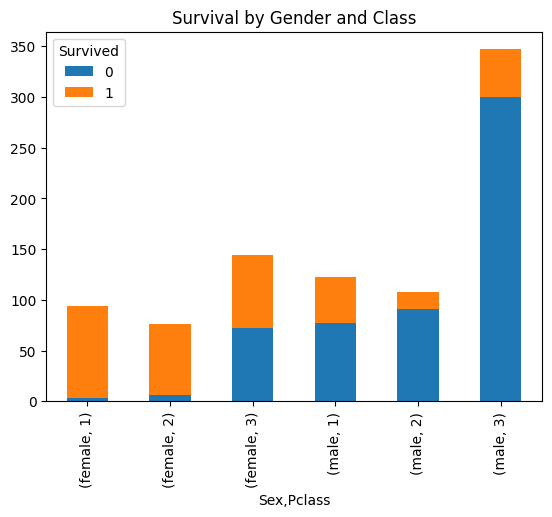

In [17]:
# Stacked Bar Plot
ct = pd.crosstab([df['Sex'], df['Pclass']], df['Survived'])
ct.plot(kind='bar', stacked=True, title='Survival by Gender and Class')

# Crosstab with aggregation

In [18]:
ct = pd.crosstab(df['Sex'], df['Pclass'], values=df['Fare'], aggfunc='mean')
ct

Pclass,1,2,3
Sex,,,
female,106.125798,21.970121,16.118810
male,67.226127,19.741782,12.661633


### Insight:

- Average fare paid by gender and class
- For example: Average Fare is 12.66 for male passengers who are in Pclass=3

<Axes: xlabel='Sex'>

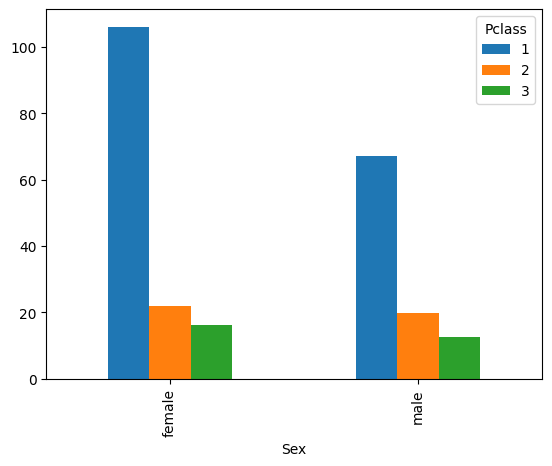

In [20]:
ct = pd.crosstab(df['Sex'], df['Pclass'], values=df['Fare'], aggfunc='mean')
ct.plot(kind='bar')